# Learning curves: how many samples does the Bayesian Network need?

This notebook produces the graphs that answer the research questions:

* **RQ2, part 1 – estimating the distribution:** how close does each estimator get to the *true* distribution (KL divergence) as the number of training samples grows?
* **RQ2, part 2 – detecting fraud:** how good is the resulting fraud detector (F1, AUROC) as the number of samples grows?
* **RQ1 (reframed):** how good a *surrogate for the distribution* is the network that Hill Climbing learns?

**How to read every graph.** The x-axis is the number of training samples. Each coloured line is one *way of estimating the probabilities*. Each line is the average over 20 independently generated ground-truth worlds; the shaded band is the 95% confidence interval of that average across ground-truth worlds. Because the true world is known exactly, every number is exact: we list all 781,250 possible transactions and weight each by its true probability, so there is no sampling noise in the *evaluation* — only in which training sample was drawn.

In [1]:
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.width", 200)
df = pd.read_csv("outputs/learning_curves_results.csv")
print(df["seed"].nunique(), "ground truths;", sorted(df["n"].unique()), "training sizes")
print("structures:", list(df["structure"].unique()), "| estimators:", list(df["estimator"].unique()))

20 ground truths; [np.int64(100), np.int64(200), np.int64(500), np.int64(1000), np.int64(2000), np.int64(5000), np.int64(10000), np.int64(20000), np.int64(50000)] training sizes
structures: ['true', 'learned', 'empty'] | estimators: ['MLE', 'Jeffreys', 'Laplace', 'FP_s1', 'FP_s2', 'FP_s3', 'FP_s4', 'FP_s10', 'FP_s25', 'FP_s50', 'FP_s100', 'FP_s200', 'FP_s500']


## The estimators being compared
| Name | What it does, in plain words |
|---|---|
| **MLE** | Trusts the raw counts exactly. Never seen it happen → probability 0. |
| **Jeffreys (α = 0.5)** | Adds half an imaginary observation to every outcome before counting. |
| **Laplace (α = 1)** | Adds one imaginary observation to every outcome. |
| **Fraud prior, strength s** | For the fraud variable only: starts from the belief "fraud is rare (0.5%)", worth *s* imaginary samples. All other variables use Jeffreys. |

The strength *s* is the hyper-parameter: a larger *s* means the belief is held more firmly.

## 1. Estimating the distribution — KL divergence vs number of samples

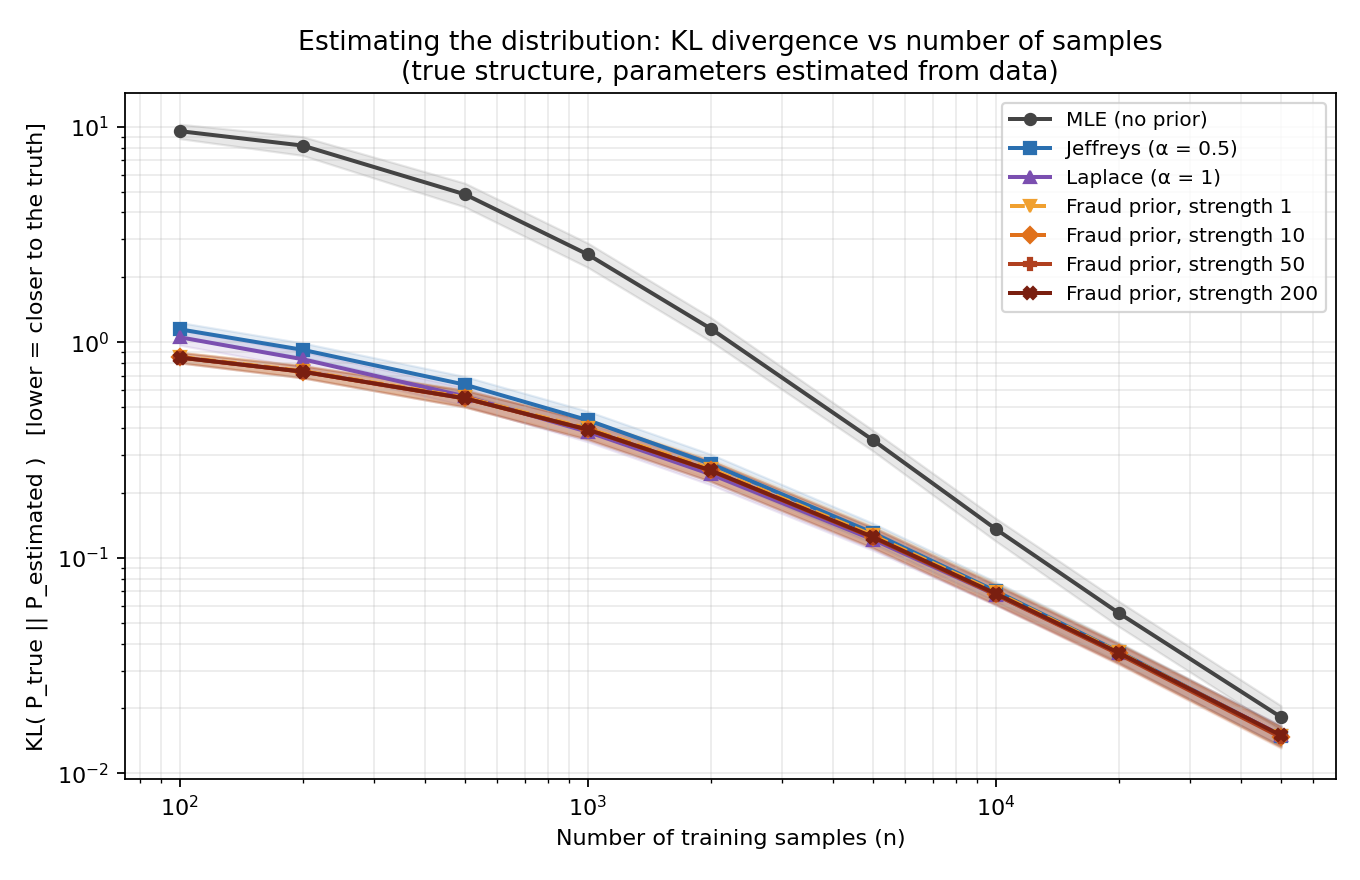

estimator,MLE,Jeffreys,Laplace,FP_s1,FP_s10,FP_s50,FP_s200
n,,,,,,,
100,9.5366,1.1482,1.0549,0.8556,0.8502,0.8496,0.8496
200,8.1754,0.9223,0.8343,0.7358,0.7310,0.7303,0.7305
500,4.8545,0.6356,0.5612,0.5547,0.5494,0.5486,0.5491
1000,2.5549,0.4351,0.3840,0.3987,0.3938,0.3928,0.3933
2000,1.1576,0.2728,0.2443,0.2590,0.2547,0.2536,0.2542
5000,0.3517,0.1304,0.1215,0.1271,0.1247,0.1241,0.1249
10000,0.1360,0.0700,0.0673,0.0693,0.0679,0.0675,0.0682
20000,0.0555,0.0367,0.0362,0.0365,0.0360,0.0357,0.0363
50000,0.0182,0.0150,0.0150,0.0149,0.0148,0.0147,0.0150


In [2]:
display(Image("outputs/figures/lc_kl_vs_n.png"))
t = df[df.structure == "true"].pivot_table(index="n", columns="estimator", values="kl", aggfunc="mean")
t[["MLE", "Jeffreys", "Laplace", "FP_s1", "FP_s10", "FP_s50", "FP_s200"]].round(4)

**What this shows.** Every line falls as more data arrives — all estimators converge on the truth. But **MLE starts far above the rest** (KL ≈ 9.5 at 100 samples versus ≈ 1 for the others) and needs tens of thousands of samples before it gets close. Adding any prior makes learning *much faster*: this is the "steep learning curve" comparison.

The four fraud-prior lines (strengths 1 → 200) lie almost on top of each other. Laplace is statistically indistinguishable from the fraud prior in KL except at 100 samples, where the fraud prior is clearly closer (paired test, Holm-corrected). KL is dominated by the many ordinary variables, so it barely notices how the single fraud variable is treated. Detection (next graph) is where the fraud prior matters.

## 2. Detecting fraud — F1 and AUROC vs number of samples

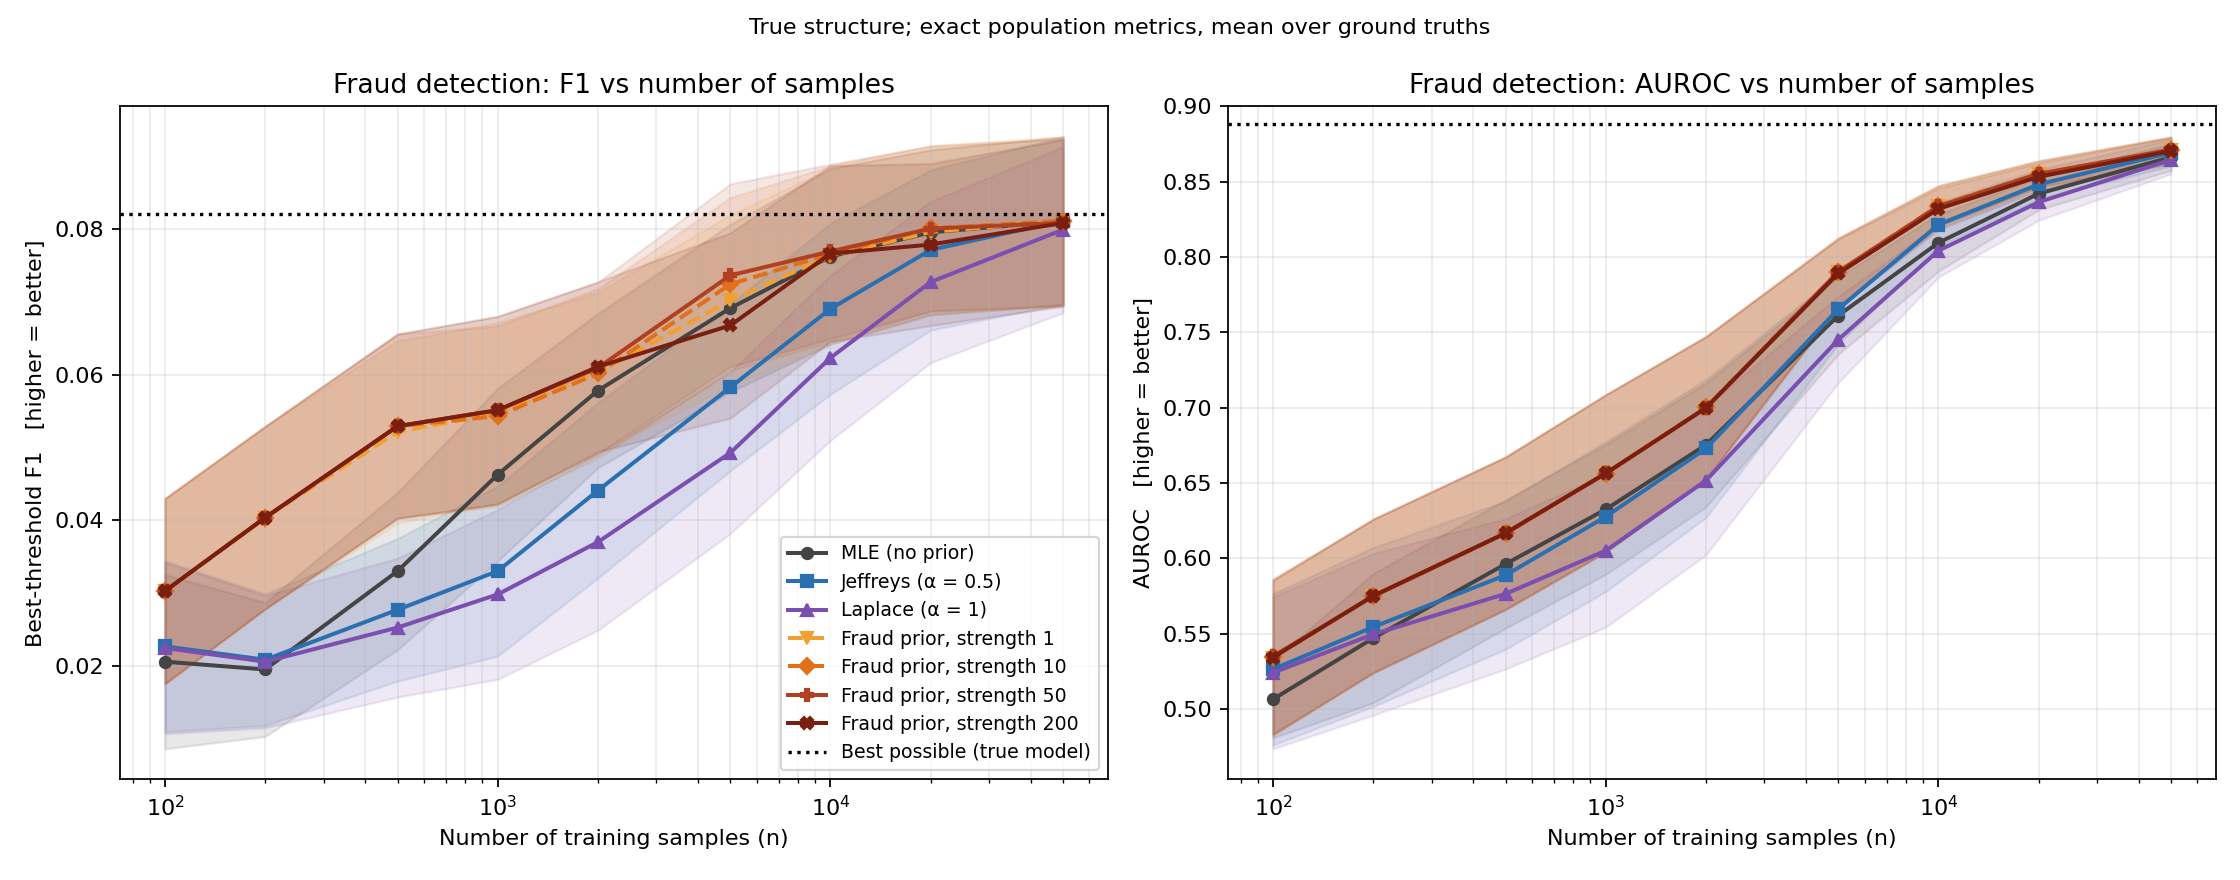

AUROC: fraud prior (s=50) minus Laplace  [positive = fraud prior better]


,mean difference,ground truths where A is better,out of
200,0.0252,15.0,20.0
500,0.0402,15.0,20.0
2000,0.0481,18.0,20.0
5000,0.0450,17.0,20.0
20000,0.0188,17.0,20.0


F1: fraud prior (s=50) minus Laplace  [positive = fraud prior better]


,mean difference,ground truths where A is better,out of
200,0.0197,13.0,20.0
500,0.0276,18.0,20.0
2000,0.0239,19.0,20.0
5000,0.0243,18.0,20.0
20000,0.0073,14.0,20.0


In [3]:
display(Image("outputs/figures/lc_detection_vs_n.png"))
T = df[df.structure == "true"]
def paired(a, b, metric, ns):
    A = T[T.estimator == a].pivot_table(index="seed", columns="n", values=metric)
    B = T[T.estimator == b].pivot_table(index="seed", columns="n", values=metric)
    out = {}
    for n in ns:
        d = A[n] - B[n]
        out[n] = {"mean difference": d.mean(), "ground truths where A is better": int((d > 0).sum()), "out of": len(d)}
    return pd.DataFrame(out).T
print("AUROC: fraud prior (s=50) minus Laplace  [positive = fraud prior better]")
display(paired("FP_s50", "Laplace", "auroc", [200, 500, 2000, 5000, 20000]).round(4))
print("F1: fraud prior (s=50) minus Laplace  [positive = fraud prior better]")
display(paired("FP_s50", "Laplace", "f1", [200, 500, 2000, 5000, 20000]).round(4))

**What this shows — and it is the opposite of the KL graph.** For *detecting* fraud the **fraud-informed prior is best** and **Laplace is worst**, especially between 500 and 5,000 samples. Paired within each ground-truth world, the fraud prior has the better AUROC than Laplace in 15–18 of the 20 worlds at every size from 200 to 20,000 samples, and the better F1 in 18–19 of 20 between 500 and 5,000 samples. After Holm correction these differences are statistically significant for AUROC from 500 samples upward and for F1 between 500 and 5,000 samples (section 7). Against plain MLE the evidence is weaker — see section 7.

**Why.** Jeffreys and Laplace silently believe "fraud is a 50/50 event". For a rare event that is a bad belief: a combination of inputs that was seen only a few times, or never, gets a fraud probability of tens of percent instead of 0.5%. Those inflated scores push ordinary transactions above real fraud and wreck the ranking. MLE has a related problem (never-seen combinations are treated as 50/50 too). A prior centred on the *right base rate* avoids this.

So **the best distribution estimator is not automatically the best fraud detector**: Laplace is among the best on KL, yet between about 500 and 20,000 samples it is the worst on F1 and AUROC.

## 3. Change the strength of the prior instead of the number of samples

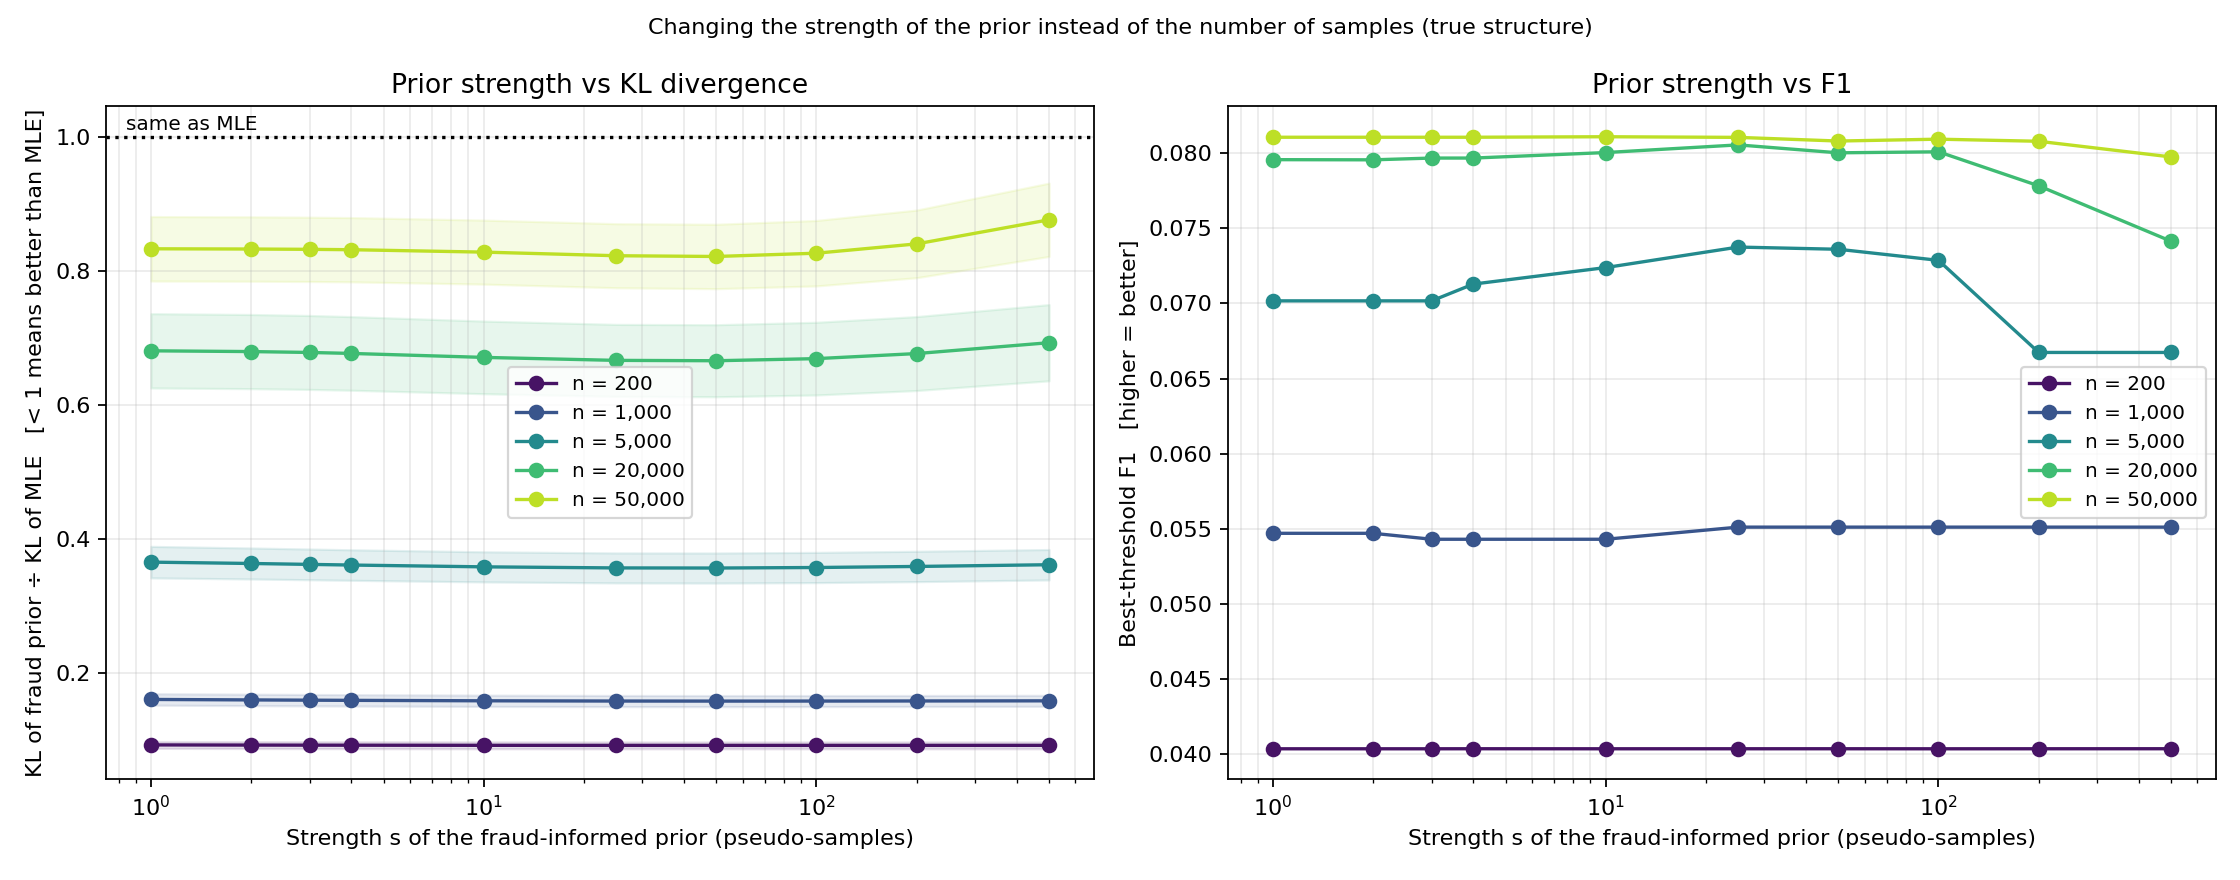

In [4]:
display(Image("outputs/figures/lc_prior_strength.png"))

**What this shows.** Moving the strength from 1 to 200 changes very little: KL is almost flat, and F1 is flat until the strength reaches about 200 imaginary samples, where it starts to hurt because the prior then overrides what the data say. When the prior's base rate is right, strength hardly matters; section 6 shows what happens when the base rate is wrong, where strength decides how much damage is done.

## 4. What if the base rate you assume is wrong?

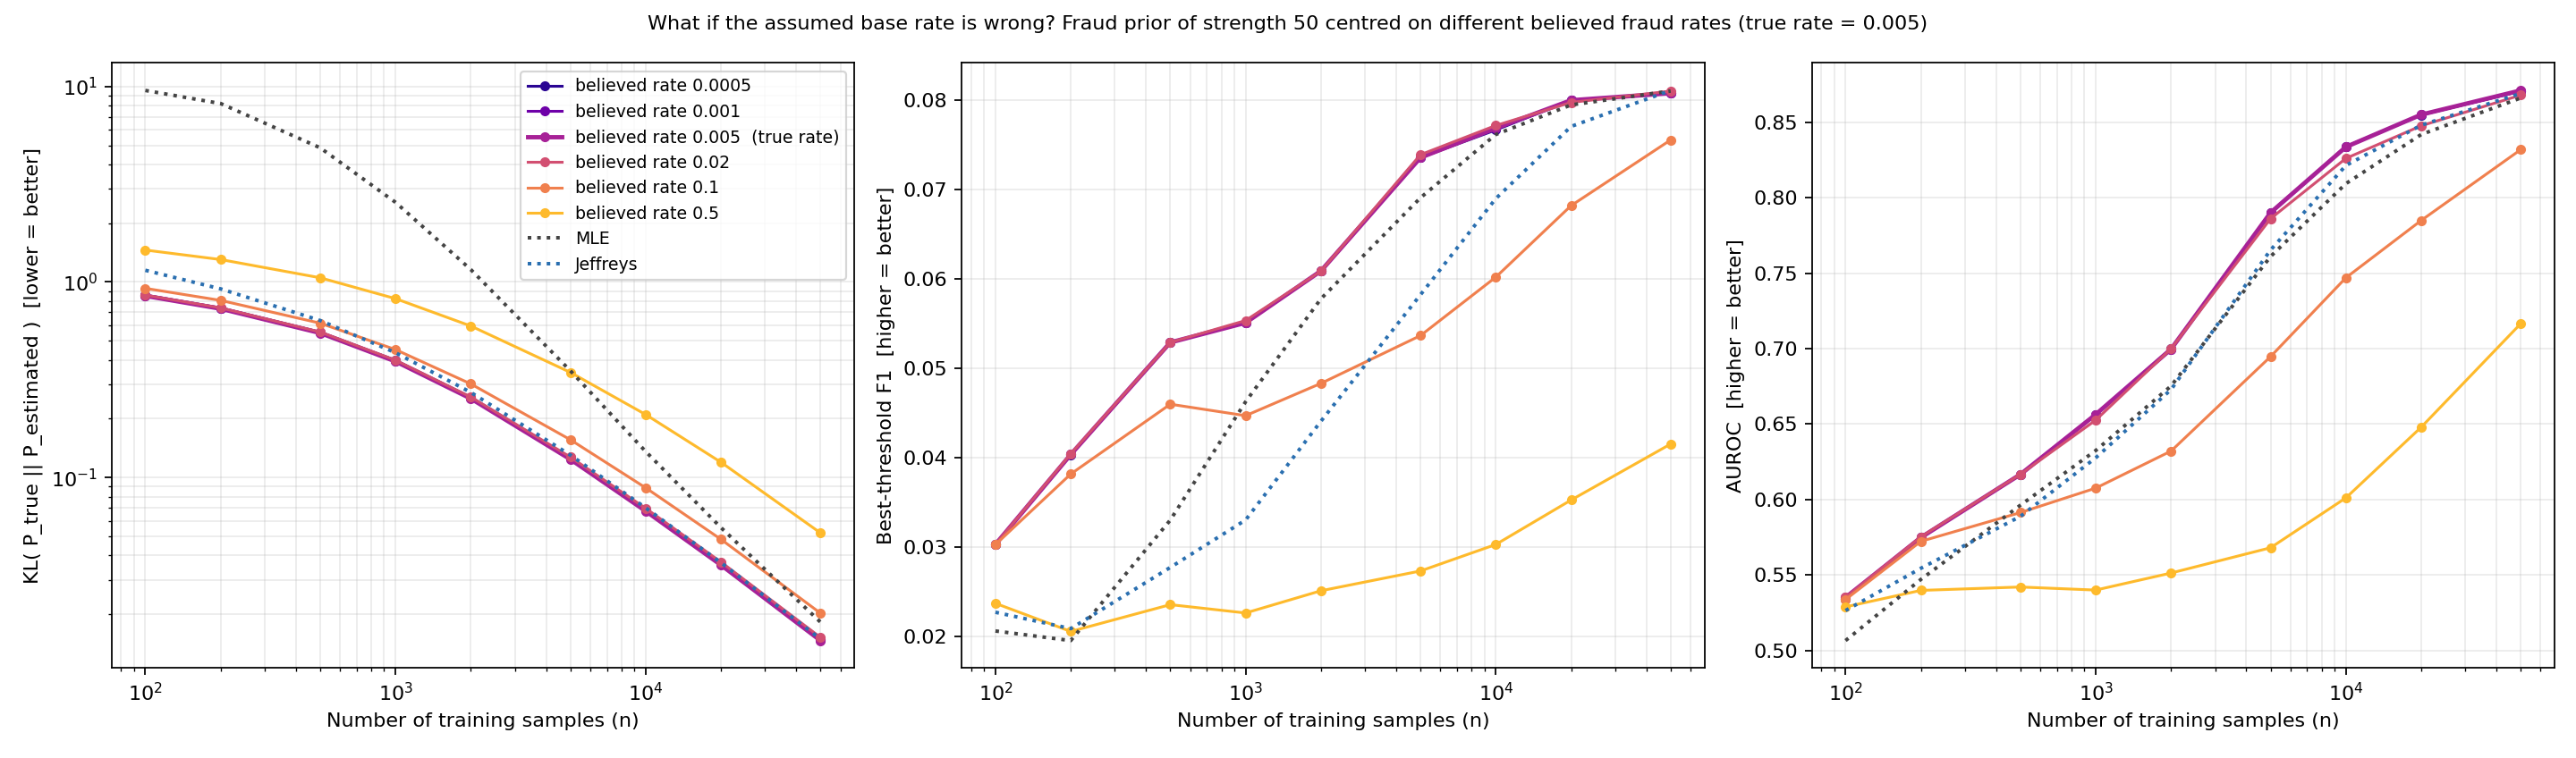

In [5]:
display(Image("outputs/figures/lc_prior_centre.png"))

**What this shows.** The true fraud rate in these worlds is 0.5%. Believing 0.05%, 0.1%, 0.5% or 2% gives practically the same results — the prior is **forgiving of a base rate that is 10× too low or 4× too high**. Only a badly wrong belief (10% or 50%) hurts, and a 50/50 belief is the worst — which is exactly what Jeffreys and Laplace implicitly assume.

## 5. RQ1 reframed — is the learned network a good surrogate for the true distribution?

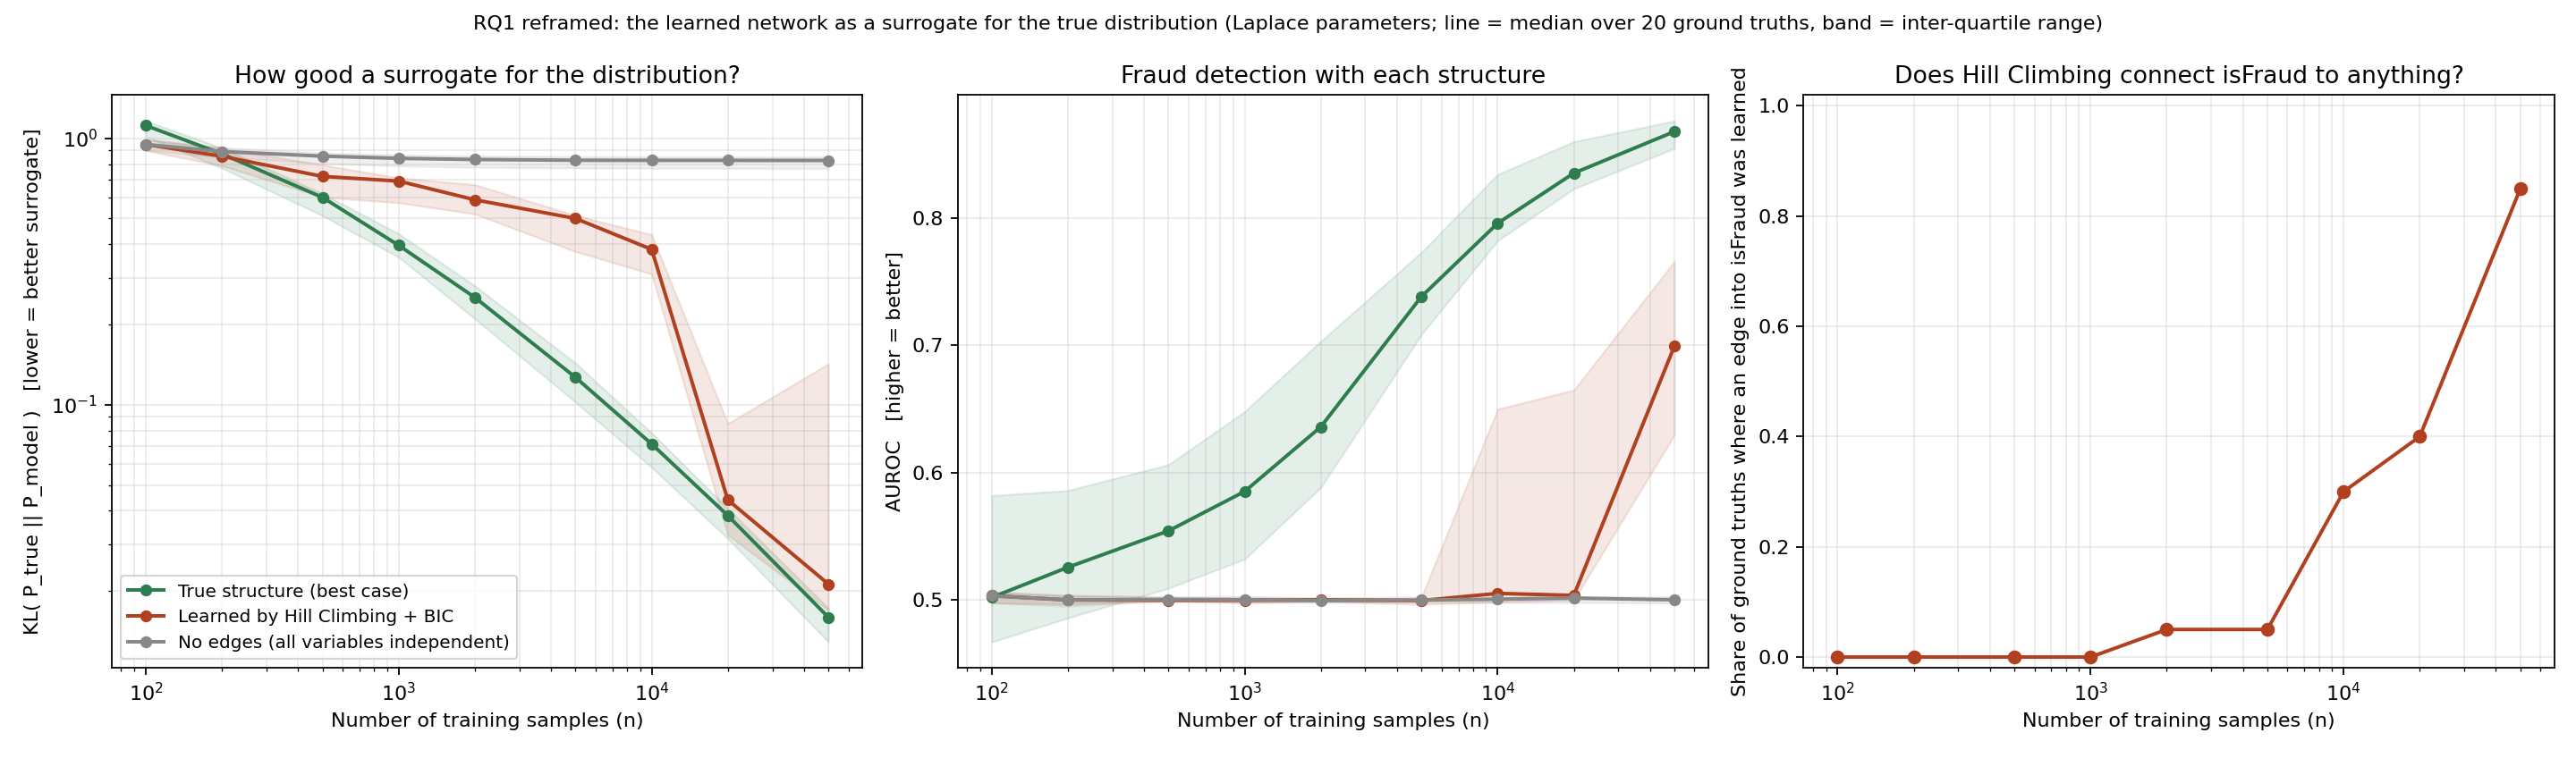

,auroc,has_fraud_edge,kl
n,,,
100,0.503,0.0,0.949
200,0.500,0.0,0.856
500,0.500,0.0,0.720
1000,0.499,0.0,0.691
2000,0.500,0.05,0.588
5000,0.499,0.05,0.500
10000,0.505,0.3,0.383
20000,0.503,0.4,0.044
50000,0.699,0.85,0.021


In [6]:
display(Image("outputs/figures/lc_rq1_surrogate.png"))
L = df[(df.structure == "learned") & (df.estimator == "Laplace")].pivot_table(index="n", values=["kl", "auroc", "has_fraud_edge"], aggfunc={"kl": "median", "auroc": "median", "has_fraud_edge": "mean"})
L.round(3)

**What this shows.** Hill Climbing is judged here by how well the network it learns *mimics the true distribution* — not by whether it reproduces the exact true arrows, which score-based methods cannot guarantee (they can only find an equivalence class of structures, and noise, identifiability and causal-direction issues all get in the way).

* The learned network improves on a model with **no edges at all** only gradually (median KL 0.72 vs 0.86 at 500 samples; 0.50 vs 0.83 at 5,000) and stays far from the true structure (0.13 at 5,000). Its fraud AUROC is about 0.5 — no detection at all — until roughly 10,000 samples.
* Between roughly 10,000 and 20,000 samples it becomes a good surrogate and at 50,000 the median learned network is close to the true structure.
* It connects `isFraud` to something in only a minority of worlds up to 20,000 samples (40%) and in most worlds (85%) only at 50,000 (right panel), so fraud detection with the learned structure lags far behind the true structure.
* Six of the 20 worlds (four of them by more than 0.05 KL) even get *worse* between 20,000 and 50,000 samples: greedy search can settle on a differently oriented network that is not equivalent to the truth. That is why the median and inter-quartile range are shown instead of the mean.

## 6. Is a stronger prior always better? (prior strength × how wrong the believed base rate is)

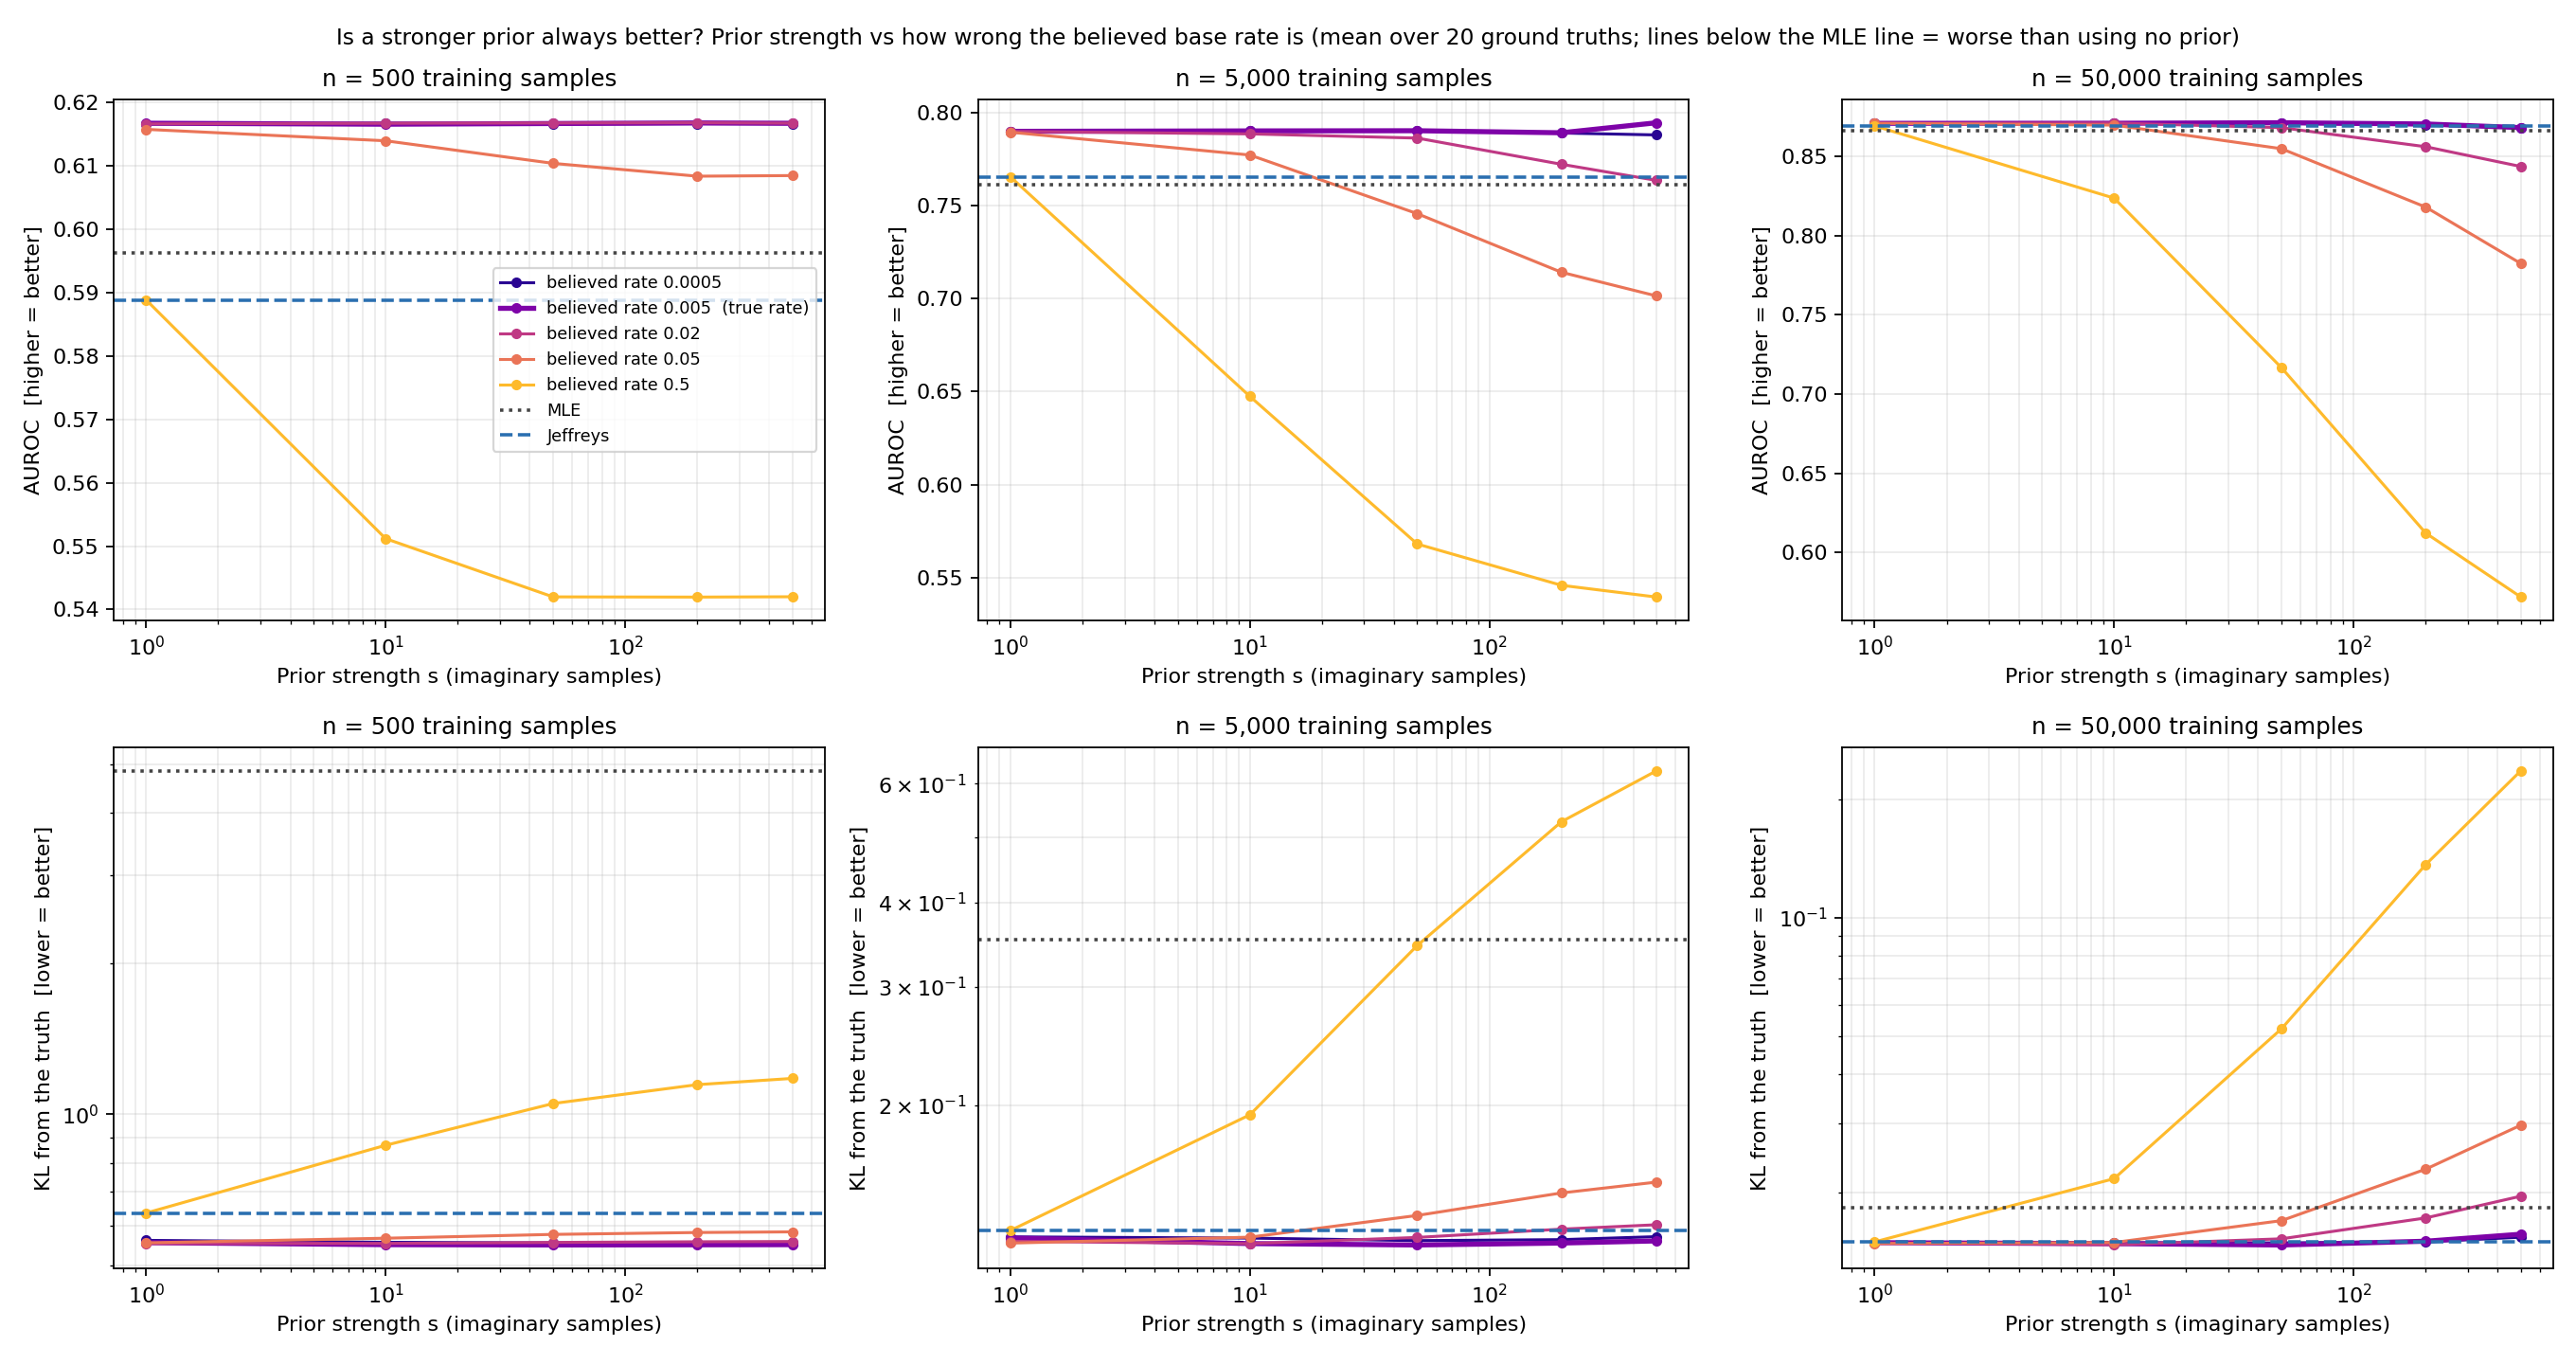

AUROC change caused by believing the base rate is 10x too high (0.05 instead of 0.005):


n,100,500,2000,5000,20000,50000
strength,,,,,,
1,0.000,-0.001,-0.001,-0.000,-0.000,0.000
10,-0.000,-0.003,-0.012,-0.013,-0.005,-0.001
50,-0.002,-0.006,-0.030,-0.045,-0.032,-0.016
200,-0.001,-0.008,-0.044,-0.075,-0.073,-0.052
500,-0.001,-0.008,-0.057,-0.093,-0.096,-0.086


Same, but the belief is 100x too high (0.5, i.e. 'fraud is 50/50'):


n,100,500,2000,5000,20000,50000
strength,,,,,,
1,-0.007,-0.028,-0.027,-0.024,-0.007,-0.002
10,-0.006,-0.065,-0.117,-0.143,-0.090,-0.047
50,-0.006,-0.075,-0.148,-0.222,-0.207,-0.155
200,-0.006,-0.075,-0.156,-0.243,-0.276,-0.258
500,-0.005,-0.075,-0.161,-0.255,-0.294,-0.296


Is a 10x-too-high belief WORSE than using no prior at all (MLE)?  AUROC(prior) - AUROC(MLE), negative = worse than MLE


n,100,200,500,1000,2000,5000,10000,20000,50000
strength,,,,,,,,,
1,0.027,NaN,0.020,NaN,0.024,0.028,NaN,0.013,0.005
10,0.027,NaN,0.018,NaN,0.013,0.016,NaN,0.008,0.004
50,0.027,NaN,0.014,NaN,-0.005,-0.016,NaN,-0.019,-0.011
200,0.027,NaN,0.012,NaN,-0.019,-0.047,NaN,-0.062,-0.048
500,0.027,NaN,0.012,NaN,-0.027,-0.060,NaN,-0.088,-0.084


In [7]:
display(Image("outputs/figures/lc_strength_by_belief.png"))
g = pd.read_csv("outputs/learning_curves_strength_centre_grid.csv")
mle5 = df[(df.structure == "true") & (df.estimator == "MLE")].pivot_table(index="n", values="auroc", aggfunc="mean")["auroc"]
a = g.pivot_table(index=["strength", "n"], columns="believed_rate", values="auroc", aggfunc="mean")
print("AUROC change caused by believing the base rate is 10x too high (0.05 instead of 0.005):")
display((a[0.05] - a[0.005]).unstack("n").round(3))
print("Same, but the belief is 100x too high (0.5, i.e. 'fraud is 50/50'):")
display((a[0.5] - a[0.005]).unstack("n").round(3))
print("Is a 10x-too-high belief WORSE than using no prior at all (MLE)?  AUROC(prior) - AUROC(MLE), negative = worse than MLE")
display((a[0.05].unstack("n") - mle5).round(3))

**What this shows — a stronger prior is *not* always better.**

* **If the believed base rate is right (or too low), strength does not matter.** AUROC is the same to three decimals for strength 1 and strength 500 at n = 500 (0.617) and almost the same at 5,000 and 50,000.
* **If it is too high, strength decides the damage.** A belief 10× too high costs at most about 0.013 AUROC at strength 10, but about 0.045 at strength 50 and 0.075 at strength 200 (n = 5,000). With 2,000 samples or more, a strength of 50 or higher makes it *worse than using no prior at all* (MLE); with 500 samples or fewer even a wrong prior still beats MLE, because MLE is so poor there. A belief only 4× too high is safe up to strength 50 at every size.
* **The damage does not fade as n grows.** With a 'fraud is 50/50' belief at strength 200, AUROC is 0.075 lower at n = 500, 0.243 lower at 5,000, 0.276 lower at 20,000 and still 0.258 lower at 50,000. The likely reason: the prior's imaginary samples are added to the *fraud* count in every parent-combination cell, and real fraud counts per cell stay tiny however large n is. For a rare event the prior is washed out only when the *fraud* count per cell exceeds the prior's strength — not when the total number of samples is large.

**Practical reading:** a *weak* prior (strength about 1–10) centred on a rough base rate keeps nearly all the benefit and is almost harmless if the rate is wrong. Strong priors should only be used when you are confident of the base rate.

## 7. How sure can we be? Paired tests across the 20 ground-truth worlds

In [8]:
S = pd.read_csv("outputs/learning_curves_stats_true_structure.csv")
V = pd.read_csv("outputs/learning_curves_prior_vs_mle_verdicts.csv")
print("Versus MLE at each n (Holm-corrected, 108 tests):  B = significantly better, W = significantly worse, . = no clear difference")
display(V)
def show(a, b, metric):
    s = S[(S.A == a) & (S.B == b) & (S.metric == metric)]
    return s[["n", "mean_diff_A_minus_B", "ci95_low", "ci95_high", "effect_size_dz", "A_better_in", "p_holm"]].round(4).set_index("n")
print("Fraud prior (s=50) minus Laplace, AUROC:"); display(show("FP_s50", "Laplace", "auroc"))
print("Fraud prior (s=50) minus Laplace, F1:"); display(show("FP_s50", "Laplace", "f1"))

Versus MLE at each n (Holm-corrected, 108 tests):  B = significantly better, W = significantly worse, . = no clear difference

,estimator,metric,100,500,2000,5000,20000,50000
0,Jeffreys,kl,B,B,B,B,B,B
1,Jeffreys,f1,.,.,W,W,.,.
2,Jeffreys,auroc,.,.,.,.,.,B
3,Laplace,kl,B,B,B,B,B,B
4,Laplace,f1,.,.,W,W,.,.
5,Laplace,auroc,.,.,.,.,.,.
6,FP_s50,kl,B,B,B,B,B,B
7,FP_s50,f1,B,B,.,.,.,.
8,FP_s50,auroc,.,.,.,B,B,B


Fraud prior (s=50) minus Laplace, AUROC:


,mean_diff_A_minus_B,ci95_low,ci95_high,effect_size_dz,A_better_in,p_holm
n,,,,,,
100,0.0110,-0.0019,0.0238,0.4002,11,1.0000
500,0.0402,0.0129,0.0676,0.6879,15,0.0149
2000,0.0481,0.0185,0.0777,0.7593,18,0.0241
5000,0.0450,0.0185,0.0715,0.7954,17,0.0417
20000,0.0188,0.0117,0.0258,1.2489,17,0.0018
50000,0.0067,0.0042,0.0092,1.2546,20,0.0002


Fraud prior (s=50) minus Laplace, F1:


,mean_diff_A_minus_B,ci95_low,ci95_high,effect_size_dz,A_better_in,p_holm
n,,,,,,
100,0.0078,0.0000,0.0156,0.4696,13,0.6224
500,0.0276,0.0170,0.0382,1.2153,18,0.0018
2000,0.0239,0.0157,0.0320,1.3722,19,0.0080
5000,0.0243,0.0152,0.0335,1.2441,18,0.0010
20000,0.0073,0.0025,0.0122,0.7084,14,0.1306
50000,0.0009,-0.0002,0.0020,0.3917,13,1.0000


**What this shows (and where I had to soften earlier claims).**

* **KL:** all three priors are significantly closer to the truth than MLE at *every* size tested, up to 50,000 samples.
* **Fraud prior vs Laplace:** significantly better AUROC from 500 samples upward and better F1 between 500 and 5,000 samples. Effect sizes are large (paired d ≈ 0.7–1.4). In absolute terms the AUROC gain is modest (about 0.02–0.05 between 500 and 20,000 samples, only 0.007 at 50,000) but consistent; the F1 gain roughly doubles F1 at 500 samples (0.025 → 0.053).
* **Fraud prior vs MLE:** the evidence is weaker than the graph suggests. It is significantly better on F1 only at 100–500 samples and on AUROC only from 5,000 samples. On AUROC at 100–2,000 samples it is better in 13–15 of 20 worlds, but the worlds differ so much in difficulty that this is not statistically clear.
* **Jeffreys and Laplace are significantly *worse* than MLE on F1 at 2,000–5,000 samples** — adding a 50/50-centred prior to a rare event can hurt detection even though it helps the distribution.

## 8. How quickly does each estimator converge, and when does the prior stop mattering?

In [9]:
conv = pd.read_csv("outputs/learning_curves_convergence.csv", index_col=0)
display(conv.round(4))
mk = df[df.structure == "true"].pivot_table(index="n", columns="estimator", values="kl", aggfunc="mean")
display((mk["MLE"] / mk[["Jeffreys", "Laplace", "FP_s50"]].min(axis=1)).round(2).rename("MLE KL ÷ best prior KL"))

,KL at n=100,"KL at n=5,000","KL at n=50,000",log-log slope (n>=1000)
estimator,,,,
MLE,9.5366,0.3517,0.0182,-1.2800
Jeffreys,1.1482,0.1304,0.0150,-0.8652
Laplace,1.0549,0.1215,0.0150,-0.8296
FP_s50,0.8496,0.1241,0.0147,-0.8443


n
100      11.23
200      11.20
500       8.85
1000      6.65
2000      4.74
5000      2.89
10000     2.02
20000     1.55
50000     1.24
Name: MLE KL ÷ best prior KL, dtype: float64

**What this shows.**

* MLE starts roughly **11× further from the truth** than the best prior at 100 samples, 4.7× at 2,000, 2.0× at 10,000 and **still 1.24× at 50,000** — the gap is shrinking but has not closed within the tested range, so for *KL* the prior has not stopped mattering by 50,000 samples.
* MLE's curve is steeper (log-log slope about −1.28 versus about −0.85 for the priors): it starts far behind and catches up faster, which is why the gap narrows.
* For *detection* the prior stops mattering sooner: F1 differences against MLE are not significant beyond 5,000 samples for Jeffreys and Laplace (and beyond 500 for the fraud prior). The fraud prior's AUROC advantage is still statistically detectable at 50,000 samples but tiny (0.005).

## 9. Do the benefits survive when the structure is learned instead of known?

In [10]:
Ls = pd.read_csv("outputs/learning_curves_learned_structure_summary.csv")
for v in ["kl", "auroc"]:
    print("median", v, "with the structure learned by Hill Climbing + BIC")
    display(Ls.pivot_table(index="n", columns="estimator", values=v).round(4))

median kl with the structure learned by Hill Climbing + BIC


estimator,FP_s50,Jeffreys,Laplace,MLE
n,,,,
100,0.9559,0.9568,0.9489,0.9870
200,0.8610,0.8592,0.8564,0.8886
500,0.7222,0.7214,0.7196,0.7410
1000,0.6917,0.6915,0.6912,0.6923
2000,0.5887,0.5887,0.5880,0.5926
5000,0.5012,0.5012,0.5003,0.5022
10000,0.3834,0.3834,0.3830,0.3840
20000,0.0468,0.0467,0.0440,0.0659
50000,0.0217,0.0217,0.0212,0.0251


median auroc with the structure learned by Hill Climbing + BIC


estimator,FP_s50,Jeffreys,Laplace,MLE
n,,,,
100,0.4996,0.5004,0.5031,0.5015
200,0.5005,0.4997,0.4998,0.4998
500,0.5004,0.5004,0.4995,0.4995
1000,0.5001,0.4996,0.4995,0.5005
2000,0.5001,0.4994,0.4999,0.4997
5000,0.4998,0.4998,0.4993,0.5003
10000,0.5032,0.5007,0.5049,0.5030
20000,0.5166,0.5267,0.5034,0.5132
50000,0.6993,0.6989,0.6995,0.6988


**What this shows.**

* **KL:** the priors still beat MLE (lower KL in 18–20 of 20 worlds at every size checked), but the improvement is small next to the error caused by the *structure* — up to 10,000 samples all four estimators have almost the same median KL (within about 4%); a clear gap appears only at 20,000 samples.
* **Detection:** with the learned structure all four estimators give practically the same AUROC (about 0.72 in worlds where an edge into `isFraud` was learned). The reason is visible in the structures: the true fraud node has on average **2.7 parents (about 100 parent-combination cells)**, while the Hill-Climbing fraud node (at 50,000 samples) has **about 1.4 parents (about 13 cells)** when it has any. With so few, densely filled cells, the sparse-cell problem the base-rate prior solves hardly arises.
* So the detection advantage of the fraud-informed prior is a **parameter-estimation effect that appears when the fraud node has many parent combinations** (as in the true structure); it does not carry over to the parsimonious structures BIC actually learns.

## Things to state honestly (threats to validity)
1. **The ground truth is synthetic.** Its probability tables were drawn from a Dirichlet(2) and its fraud tables from a Beta centred on the same 0.5% rate the fraud prior uses, so priors are given a favourable setting. The base-rate robustness graph is there to show the conclusion does not need that rate to be exact.
2. **MLE's KL is inflated at small n** partly by the 1e-4 probability floor (zero counts cannot be logged). Another floor would move the MLE curve but not the ranking.
3. **F1 is the best F1 over all thresholds**, chosen with knowledge of the labels, so absolute F1 values are optimistic; comparisons between estimators are still fair.
4. **Hill Climbing is one greedy run** with no restarts.
5. The F1 values are small in absolute terms because fraud is 0.5% of transactions (the best possible F1 here is about 0.08).
6. All conclusions come from one family of randomly generated worlds (9 variables, at most 3 parents per node). The pseudo-count strength is applied **per parent-combination cell**, so its effect depends on how many cells the fraud node has.
7. The statistical tests treat the 20 worlds as independent; p-values are Holm-corrected over 108 comparisons, but they describe these synthetic worlds, not real data.

## Re-running everything
```bash
PYTHONHASHSEED=0 python learning_curves.py 20 0 outputs/learning_curves_results.csv   # ~7 minutes
PYTHONHASHSEED=0 python prior_centre_check.py                                          # ~1 minute
python plot_learning_curves.py                                                         # figures + summary tables
```